## Initialising

In [1]:
import pandas as pd

df = pd.read_csv("dataset/student_performance_dirty.csv")

In [2]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index,Notes
0,7.0,99,Yes,9.0,1,91.0,excellent
1,4.0,82,No,4.0,2,65.0,review
2,8.0,51,Yes,7.0,2,45.0,review
3,5.0,52,Yes,5.0,2,36.0,excellent
4,7.0,75,No,8.0,5,66.0,review


In [3]:
df = df.drop('Notes', axis = 1)

In [4]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7.0,99,Yes,9.0,1,91.0
1,4.0,82,No,4.0,2,65.0
2,8.0,51,Yes,7.0,2,45.0
3,5.0,52,Yes,5.0,2,36.0
4,7.0,75,No,8.0,5,66.0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10005 entries, 0 to 10004
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     8973 non-null   float64
 1   Previous Scores                   10005 non-null  int64  
 2   Extracurricular Activities        10005 non-null  object 
 3   Sleep Hours                       9509 non-null   float64
 4   Sample Question Papers Practiced  10005 non-null  int64  
 5   Performance Index                 10005 non-null  float64
dtypes: float64(3), int64(2), object(1)
memory usage: 469.1+ KB


In [6]:
df.isnull().sum().sum()

np.int64(1528)

In [7]:
df.duplicated().sum()

np.int64(98)

In [12]:
df = df.drop_duplicates()

In [13]:
df.duplicated().sum()

np.int64(0)

In [15]:
#clean boxes

In [ ]:
df.columns
#Hours Studied
#Previous Score
#Extracurricular Activities
#Sleep Hours

# ------------ target --------------
#Performance Index 

Index(['Hours Studied', 'Previous Scores', 'Extracurricular Activities',
       'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index'],
      dtype='object')

In [17]:
import numpy as np

limits = {
    "Hours Studied": 24, 
    "Previous Scores": 100,  # Added 's'
    "Sleep Hours": 24
}

for col, top in limits.items():
    df.loc[df[col] > top, col] = np.nan

# Used bracket notation for columns with spaces
df.loc[df["Sleep Hours"] < 0, "Sleep Hours"] = np.nan
df = df[df["Performance Index"] <= 100]

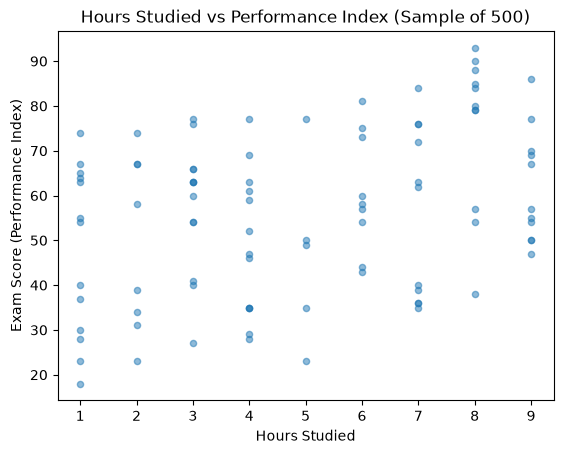

In [ ]:
import matplotlib.pyplot as plt

sample_df = df.sample(n=100, random_state=42)

plt.scatter(sample_df["Hours Studied"], sample_df["Performance Index"], alpha=0.5, s=20)
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score (Performance Index)")
plt.title("Hours Studied vs Performance Index (Sample of 500)")
plt.show()

In [32]:
# Convert Yes/No to 1/0
df['Extracurricular Activities'] = df['Extracurricular Activities'].map({'Yes': 1, 'No': 0})

In [33]:
from sklearn.model_selection import( train_test_split )

X = df[['Hours Studied', 'Previous Scores','Extracurricular Activities', 'Sleep Hours' ]]
y = df['Performance Index']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [34]:
medians = X_train.median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

In [37]:
#Model
from sklearn.ensemble import ( RandomForestRegressor)

model = RandomForestRegressor(random_state= 42)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [38]:
from sklearn.metrics import mean_absolute_error

predictions = model.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
print("MAE: ", round(mae, 1))

MAE:  2.6


In [47]:
import pandas as pd

new_student = pd.DataFrame({
    "Hours Studied": [15.0],
    "Previous Scores": [75],
    "Extracurricular Activities": [1],  # 1 for Yes, 0 for No
    "Sleep Hours": [8.0]
})

score = model.predict(new_student)[0]
print("Predicted score:", round(score, 2))

Predicted score: 72.51
